# Arquitectura LeNet-5 para Fashion Mnist
## Proyecto de Aprendizaje Profundo

Diego Octavio Arias Incháustegui, Jose Alejandro Rojas Castro, Josh Haberkern,Steffany Mishell Lara Muy
*Instituto Tecnológico y de Estudios Superiores de Monterrey (ITESM)*

**Resumen**
TERMINAAAR
}

In [1]:
import argparse
import os
import json
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [2]:
# Establecer semillas aleatorias para reproducibilidad
def set_seeds(seed=42):
    """Set seeds for reproducibility"""
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

In [3]:
class FashionMNISTDataLoader:
    """Cargador de datos para Fashion-MNIST con aumento"""

    CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    def __init__(self, val_split=0.1, seed=42):
        self.val_split = val_split
        self.seed = seed
        self.load_data()

    def load_data(self):
        """ Fashion-MNIST data"""
        # cargar Fashion-MNIST
        (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

        # Split train en los train/val
        x_train, x_val, y_train, y_val = train_test_split(
            x_train_full, y_train_full,
            test_size=self.val_split,
            random_state=self.seed,
            stratify=y_train_full
        )

        # Reshape para la CNN  agregando dimensión del canal
        x_train = x_train.reshape(-1, 28, 28, 1).astype('float32')
        x_val = x_val.reshape(-1, 28, 28, 1).astype('float32')
        x_test = x_test.reshape(-1, 28, 28, 1).astype('float32')

        # Normalizar to [0, 1]
        self.mean = x_train.mean()
        self.std = x_train.std()
        x_train = (x_train - self.mean) / self.std
        x_val = (x_val - self.mean) / self.std
        x_test = (x_test - self.mean) / self.std

        # Covertir a categoricas las labels
        y_train = keras.utils.to_categorical(y_train, 10)
        y_val = keras.utils.to_categorical(y_val, 10)
        y_test = keras.utils.to_categorical(y_test, 10)

        self.x_train, self.y_train = x_train, y_train
        self.x_val, self.y_val = x_val, y_val
        self.x_test, self.y_test = x_test, y_test

        print(f"Training samples: {len(x_train)}")
        print(f"Validation samples: {len(x_val)}")
        print(f"Test samples: {len(x_test)}")

    def get_augmentation(self):
        """ data augmentation pipeline"""
        return keras.Sequential([
            layers.RandomTranslation(0.1, 0.1),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ])



In [4]:

class EnhancedLeNet5:
    """arquitectura LeNet-5"""

    def __init__(self, input_shape=(28, 28, 1), num_classes=10,
                 dropout_rate=0.2, weight_decay=1e-4):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.dropout_rate = dropout_rate
        self.weight_decay = weight_decay
        self.model = None

    def build_model(self):
        """Construir el modelo LeNet-5 mejorado"""
        inputs = layers.Input(shape=self.input_shape)

        # Data augmentation (solo para el training)
        augmentation = keras.Sequential([
            layers.RandomTranslation(0.1, 0.1),
            layers.RandomRotation(0.1),
        ])
        x = augmentation(inputs, training=True)

        # C1: Convolutional Layer
        x = layers.Conv2D(
            32, (5, 5),
            padding='same',
            kernel_regularizer=regularizers.l2(self.weight_decay)
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)

        # S2: Pooling Layer
        x = layers.MaxPooling2D((2, 2))(x)

        # C3: Convolutional Layer
        x = layers.Conv2D(
            64, (5, 5),
            padding='valid',
            kernel_regularizer=regularizers.l2(self.weight_decay)
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)

        # S4: Pooling Layer
        x = layers.MaxPooling2D((2, 2))(x)

        # Aplanar:)
        x = layers.Flatten()(x)

        # FC5: Fully Connected Layer
        x = layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(self.weight_decay)
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(self.dropout_rate)(x)

        # FC6: Fully Connected Layer
        x = layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(self.weight_decay)
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(self.dropout_rate)(x)

        # Output Layer
        outputs = layers.Dense(self.num_classes, activation='softmax')(x)

        self.model = keras.Model(inputs, outputs, name='Enhanced_LeNet5')
        return self.model

    def get_model_summary(self):
        """Imprimir el summary de nuestro modelo"""
        if self.model is None:
            self.build_model()
        return self.model.summary()


In [5]:


class ModelTrainer:
    """Canal de entrenamiento con callbacks  y monitorización"""

    def __init__(self, model, output_dir='runs'):
        self.model = model
        self.timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
        self.output_dir = Path(output_dir) / self.timestamp
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.history = None

    def compile_model(self, learning_rate=0.001, optimizer='adamw',
                     label_smoothing=0.1):
        """Compilar con optimizar adam """
        # Select optimizer
        if optimizer.lower() == 'adamw':
            opt = keras.optimizers.AdamW(learning_rate=learning_rate)
        elif optimizer.lower() == 'sgd':
            opt = keras.optimizers.SGD(
                learning_rate=learning_rate,
                momentum=0.9,
                nesterov=True
            )
        else:
            opt = keras.optimizers.Adam(learning_rate=learning_rate)

        # Compilar con label smoothing
        self.model.compile(
            optimizer=opt,
            loss=keras.losses.CategoricalCrossentropy(
                label_smoothing=label_smoothing
            ),
            metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3)]
        )

    def get_callbacks(self, patience=10):
        """Crear callbacks de entrenamiento"""
        callbacks = [
            # Model checkpoint
            keras.callbacks.ModelCheckpoint(
                filepath=str(self.output_dir / 'best_model.h5'),
                monitor='val_accuracy',
                save_best_only=True,
                save_weights_only=False,
                mode='max',
                verbose=1
            ),

            # Early stopping por si es necesario
            keras.callbacks.EarlyStopping(
                monitor='val_accuracy',
                patience=patience,
                restore_best_weights=True,
                verbose=1
            ),

            # Reducir el learning plateau
            keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss',
                factor=0.5,
                patience=5,
                min_lr=1e-6,
                verbose=1
            ),

            # CSV logger
            keras.callbacks.CSVLogger(
                str(self.output_dir / 'training_log.csv')
            ),

            # TensorBoard
            keras.callbacks.TensorBoard(
                log_dir=str(self.output_dir / 'tensorboard'),
                histogram_freq=1
            )
        ]
        return callbacks

    def train(self, x_train, y_train, x_val, y_val,
             epochs=50, batch_size=128, use_mixed_precision=False):
        """Entrenar el modelo"""

        if use_mixed_precision:
            policy = keras.mixed_precision.Policy('mixed_float16')
            keras.mixed_precision.set_global_policy(policy)

        # Entrenar modelo
        self.history = self.model.fit(
            x_train, y_train,
            validation_data=(x_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            callbacks=self.get_callbacks(),
            verbose=1
        )

        return self.history

    def evaluate(self, x_test, y_test, batch_size=128):
        """Evaluar el modelo en el test set"""
        results = self.model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)

        # #predicciones
        y_pred = self.model.predict(x_test, batch_size=batch_size)
        y_pred_classes = np.argmax(y_pred, axis=1)
        y_true_classes = np.argmax(y_test, axis=1)

        # Classification report
        report = classification_report(
            y_true_classes, y_pred_classes,
            target_names=FashionMNISTDataLoader.CLASSES,
            output_dict=True
        )

        # Confusion matrix
        cm = confusion_matrix(y_true_classes, y_pred_classes)

        return {
            'test_loss': results[0],
            'test_accuracy': results[1],
            'top3_accuracy': results[2] if len(results) > 2 else None,
            'classification_report': report,
            'confusion_matrix': cm
        }

    def plot_training_history(self):
        """Plotear las curvas de aprendizaje"""
        if self.history is None:
            return

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Accuracy plot
        axes[0].plot(self.history.history['accuracy'], label='Train')
        axes[0].plot(self.history.history['val_accuracy'], label='Validation')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Accuracy')
        axes[0].set_title('Model Accuracy')
        axes[0].legend()
        axes[0].grid(True)

        # Loss plot
        axes[1].plot(self.history.history['loss'], label='Train')
        axes[1].plot(self.history.history['val_loss'], label='Validation')
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Loss')
        axes[1].set_title('Model Loss')
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.savefig(self.output_dir / 'training_curves.png', dpi=150)
        plt.show()

    def plot_confusion_matrix(self, cm, class_names):
        """graficar confusion matrix"""
        plt.figure(figsize=(10, 8))
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names
        )
        plt.xlabel('Predicted')
        plt.ylabel('True')
        plt.title('Confusion Matrix')
        plt.tight_layout()
        plt.savefig(self.output_dir / 'confusion_matrix.png', dpi=150)
        plt.show()

    def save_report(self, results):
        """Reporte de evaluación: guarda archivos y también imprime el resumen en consola"""
        # Normaliza valores esperados
        top3 = results.get('top3_accuracy', None)

        report = {
            'timestamp': self.timestamp,
            'test_accuracy': float(results['test_accuracy']),
            'test_loss': float(results['test_loss']),
            'top3_accuracy': float(top3) if top3 is not None else None,
            'per_class_metrics': results['classification_report']
        }

        # Guardar JSON
        with open(self.output_dir / 'evaluation_report.json', 'w') as f:
            json.dump(report, f, indent=2, ensure_ascii=False)

        # Construir texto del reporte
        lines = []
        lines.append("Fashion-MNIST LeNet-5 Evaluation Report")
        lines.append("=" * 50)
        lines.append(f"Timestamp: {self.timestamp}")
        lines.append(f"Test Accuracy: {results['test_accuracy']:.4f}")
        lines.append(f"Test Loss: {results['test_loss']:.4f}")
        if top3 is not None:
            lines.append(f"Top-3 Accuracy: {float(top3):.4f}")
        lines.append("")
        lines.append("Per-Class Performance:")
        lines.append("-" * 50)

        for class_name in FashionMNISTDataLoader.CLASSES:
            metrics = results['classification_report'][class_name]
            precision = float(metrics.get('precision', float('nan')))
            recall = float(metrics.get('recall', float('nan')))
            f1 = float(metrics.get('f1-score', float('nan')))
            lines.append(f"{class_name:15s} - Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

        text_report = "\n".join(lines)

        # Guardar TXT
        with open(self.output_dir / 'evaluation_report.txt', 'w') as f:
            f.write(text_report + "\n")

        # Imprimir en consola (lo que pediste)
        print(text_report)



Cargando el dataset de Fashion MNIST...
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 54000
Validation samples: 6000
Test samples: 10000

Construyendo el modelo LeNet-5...


2025-09-13 11:02:30.819627: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2025-09-13 11:02:30.819648: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 36.00 GB
2025-09-13 11:02:30.819656: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 13.50 GB
2025-09-13 11:02:30.819706: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-09-13 11:02:30.819723: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "Enhanced_LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 498,058 (1.90 MB)

...

422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8484 - loss: 0.7555 - top_k_categorical_accuracy: 0.9824 - val_accuracy: 0.8742 - val_loss: 0.6861 - val_top_k_categorical_accuracy: 0.9883 - learning_rate: 0.0015
Epoch 35/50
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8469 - loss: 0.7552 - top_k_categorical_accuracy: 0.9826
Epoch 35: val_accuracy did not improve from 0.87417
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8485 - loss: 0.7539 - top_k_categorical_accuracy: 0.9824 - val_accuracy: 0.8612 - val_loss: 0.7072 - val_top_k_categorical_accuracy: 0.9893 - learning_rate: 0.0015
Epoch 36/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8473 - loss: 0.7556 - top_k_categorical_accuracy: 0.9813
Epoch 36: val_accuracy improved from 0.87417 to 0.88050, saving model to runs/20250913_110231/best_model.h5


422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8480 - loss: 0.7536 - top_k_categorical_accuracy: 0.9820 - val_accuracy: 0.8805 - val_loss: 0.6703 - val_top_k_categorical_accuracy: 0.9895 - learning_rate: 0.0015
Epoch 37/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8493 - loss: 0.7545 - top_k_categorical_accuracy: 0.9825
Epoch 37: val_accuracy did not improve from 0.88050
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.8500 - loss: 0.7542 - top_k_categorical_accuracy: 0.9822 - val_accuracy: 0.8498 - val_loss: 0.7256 - val_top_k_categorical_accuracy: 0.9865 - learning_rate: 0.0015
Epoch 38/50
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8479 - loss: 0.7533 - top_k_categorical_accuracy: 0.9826
Epoch 38: val_accuracy did not improve from 0.88050
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8483 - loss: 0.7541 - top_k_categorical_accuracy: 0.9822 - val_accuracy: 0.8728 - val_loss: 0.6763 - val_top_k_categorical_accuracy: 0.9902 - learn

422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8507 - loss: 0.7541 - top_k_categorical_accuracy: 0.9819 - val_accuracy: 0.8817 - val_loss: 0.6624 - val_top_k_categorical_accuracy: 0.9885 - learning_rate: 0.0015
Epoch 41/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8475 - loss: 0.7530 - top_k_categorical_accuracy: 0.9829
Epoch 41: val_accuracy did not improve from 0.88167
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.8489 - loss: 0.7524 - top_k_categorical_accuracy: 0.9828 - val_accuracy: 0.8758 - val_loss: 0.6789 - val_top_k_categorical_accuracy: 0.9877 - learning_rate: 0.0015
Epoch 42/50
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8468 - loss: 0.7555 - top_k_categorical_accuracy: 0.9819
Epoch 42: val_accuracy did not improve from 0.88167
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - accuracy: 0.8481 - loss: 0.7534 - top_k_categorical_accuracy: 0.9830 - val_accuracy: 0.8770 - val_loss: 0.6837 - val_top_k_categorical_accuracy: 0.9862 - learn

422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.8648 - loss: 0.6949 - top_k_categorical_accuracy: 0.9857 - val_accuracy: 0.8847 - val_loss: 0.6337 - val_top_k_categorical_accuracy: 0.9872 - learning_rate: 7.5000e-04
Epoch 49/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8656 - loss: 0.6901 - top_k_categorical_accuracy: 0.9864
Epoch 49: val_accuracy did not improve from 0.88467
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.8649 - loss: 0.6898 - top_k_categorical_accuracy: 0.9867 - val_accuracy: 0.8803 - val_loss: 0.6416 - val_top_k_categorical_accuracy: 0.9892 - learning_rate: 7.5000e-04
Epoch 50/50
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8637 - loss: 0.6929 - top_k_categorical_accuracy: 0.9855
Epoch 50: val_accuracy improved from 0.88467 to 0.88550, saving model to runs/20250913_110231/best_model.h5


422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.8648 - loss: 0.6899 - top_k_categorical_accuracy: 0.9858 - val_accuracy: 0.8855 - val_loss: 0.6294 - val_top_k_categorical_accuracy: 0.9898 - learning_rate: 7.5000e-04
Restoring model weights from the end of the best epoch: 50.

Entrenamiento finalizado en 834.45 segundos

Evaluando en el set de test...
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Test Accuracy: 0.8710
Test Loss: 0.6615
Top-3 Accuracy: 0.9859


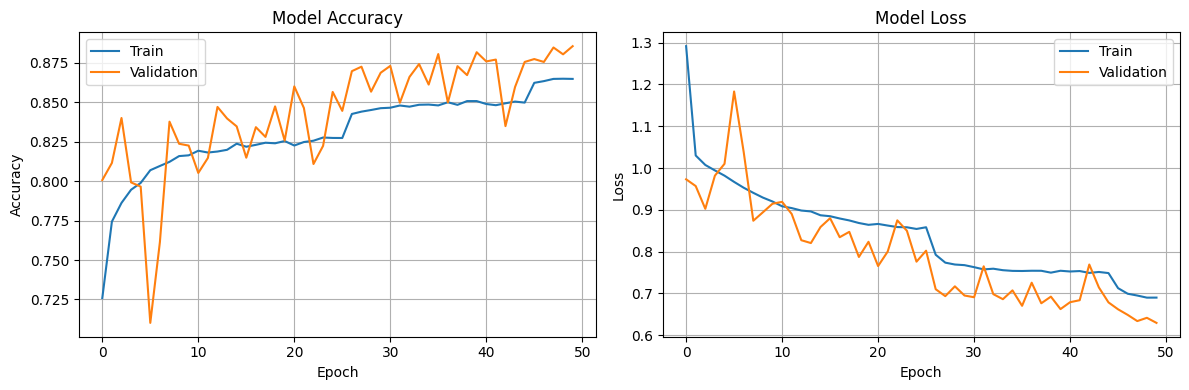

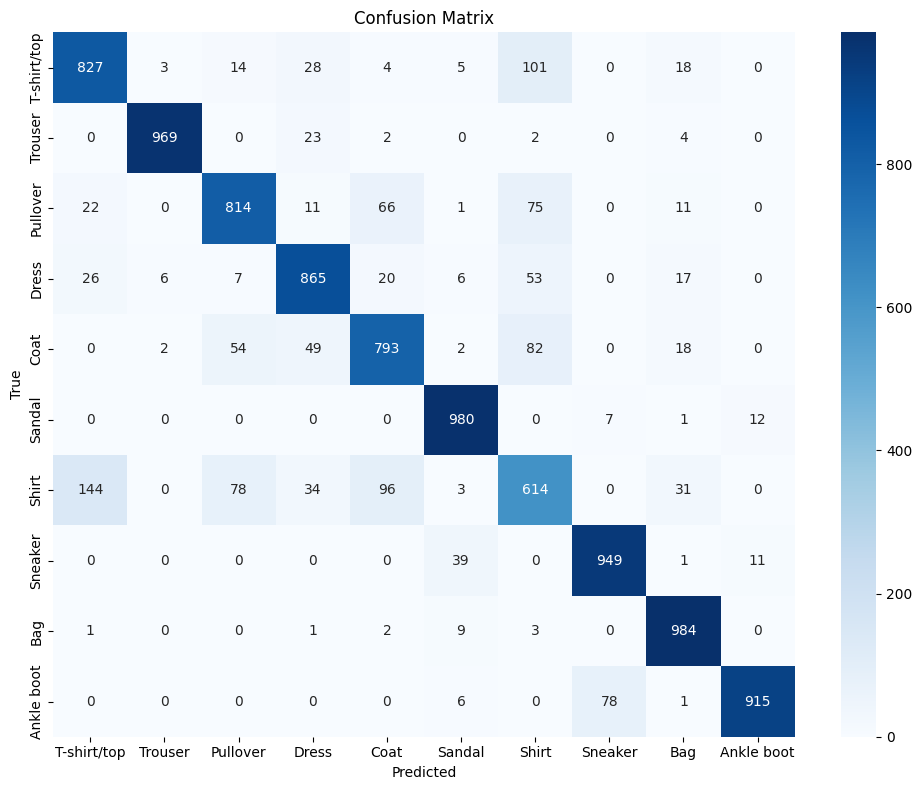

Fashion-MNIST LeNet-5 Evaluation Report
Timestamp: 20250913_110231
Test Accuracy: 0.8710
Test Loss: 0.6615
Top-3 Accuracy: 0.9859

Per-Class Performance:
--------------------------------------------------
T-shirt/top     - Precision: 0.811, Recall: 0.827, F1: 0.819
Trouser         - Precision: 0.989, Recall: 0.969, F1: 0.979
Pullover        - Precision: 0.842, Recall: 0.814, F1: 0.828
Dress           - Precision: 0.856, Recall: 0.865, F1: 0.860
Coat            - Precision: 0.807, Recall: 0.793, F1: 0.800
Sandal          - Precision: 0.932, Recall: 0.980, F1: 0.956
Shirt           - Precision: 0.660, Recall: 0.614, F1: 0.636
Sneaker         - Precision: 0.918, Recall: 0.949, F1: 0.933
Bag             - Precision: 0.906, Recall: 0.984, F1: 0.943
Ankle boot      - Precision: 0.975, Recall: 0.915, F1: 0.944

Results saved to: runs/20250913_110231

Top Confused Pairs:
  T-shirt/top -> Shirt: 101
  Shirt -> T-shirt/top: 144


In [6]:

def main():
    parser = argparse.ArgumentParser(description='Fashion-MNIST with Enhanced LeNet-5')
    parser.add_argument('--epochs', type=int, default=50, help='Number of epochs')
    parser.add_argument('--batch-size', type=int, default=128, help='Batch size')
    parser.add_argument('--lr', type=float, default=0.003, help='Learning rate')
    parser.add_argument('--optimizer', type=str, default='adamw',
                       choices=['adamw', 'sgd', 'adam'], help='Optimizer')
    parser.add_argument('--weight-decay', type=float, default=1e-3, help='Weight decay')
    parser.add_argument('--dropout', type=float, default=0.2, help='Dropout rate')
    parser.add_argument('--label-smoothing', type=float, default=0.05, help='Label smoothing')
    parser.add_argument('--seed', type=int, default=42, help='Random seed')
    parser.add_argument('--amp', type=int, default=1, help='Use mixed precision (0/1)')
    parser.add_argument('--data-dir', type=str, default='data', help='Data directory')
    parser.add_argument('--out-dir', type=str, default='runs', help='Output directory')

    args = parser.parse_known_args()[0]


    # Poner los seeds
    set_seeds(args.seed)

    # Cargar la data
    print("Cargando el dataset de Fashion MNIST...")
    data_loader = FashionMNISTDataLoader(val_split=0.1, seed=args.seed)

    # Construir el modelo
    print("\nConstruyendo el modelo LeNet-5...")
    lenet = EnhancedLeNet5(
        input_shape=(28, 28, 1),
        num_classes=10,
        dropout_rate=args.dropout,
        weight_decay=args.weight_decay
    )
    model = lenet.build_model()
    model.summary()

    # Entrenador
    trainer = ModelTrainer(model, output_dir=args.out_dir)
    trainer.compile_model(
        learning_rate=args.lr,
        optimizer=args.optimizer,
        label_smoothing=args.label_smoothing
    )

    # Entrenar el modelo
    print(f"\nEntrenando para {args.epochs} épocas...")
    start_time = time.time()

    history = trainer.train(
        data_loader.x_train, data_loader.y_train,
        data_loader.x_val, data_loader.y_val,
        epochs=args.epochs,
        batch_size=args.batch_size,
        use_mixed_precision=bool(args.amp)
    )

    training_time = time.time() - start_time
    print(f"\nEntrenamiento finalizado en {training_time:.2f} segundos")

    # Evaluar el modelo
    print("\nEvaluando en el set de test...")
    results = trainer.evaluate(data_loader.x_test, data_loader.y_test)

    print(f"\nTest Accuracy: {results['test_accuracy']:.4f}")
    print(f"Test Loss: {results['test_loss']:.4f}")
    if results['top3_accuracy']:
        print(f"Top-3 Accuracy: {results['top3_accuracy']:.4f}")

    #  Guardar los resultados
    trainer.plot_training_history()
    trainer.plot_confusion_matrix(
        results['confusion_matrix'],
        FashionMNISTDataLoader.CLASSES
    )
    trainer.save_report(results)

    print(f"\nResults saved to: {trainer.output_dir}")

    # Print final summary
    print("\nTop Confused Pairs:")
    cm = results['confusion_matrix']
    for i in range(10):
        for j in range(10):
            if i != j and cm[i, j] > 100:  # Threshold for significant confusion
                print(f"  {FashionMNISTDataLoader.CLASSES[i]} -> "
                     f"{FashionMNISTDataLoader.CLASSES[j]}: {cm[i, j]}")


if __name__ == '__main__':
    main()